Файл загружен успешно

=== ЗАДАНИЕ 1 ===



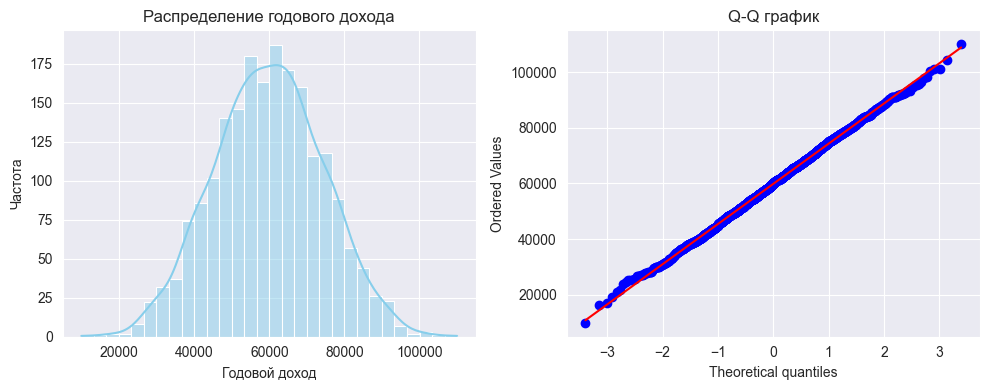

Тест Шапиро-Уилка: p-value = 6.3626e-01
Результат: Распределение Annual_Income соответствует НОРМАЛЬНОМУ (p > 0.05)

--- Средний годовой доход по полу ---
Gender
Female    60031.627530
Male      59671.703557
Name: Annual_Income, dtype: float64
Средний доход мужчин: 59671.70
Средний доход женщин: 60031.63

--- Сравнение среднего дохода мужчин и женщин ---
Использован t-тест: p-value = 5.7775e-01
Результат: НЕТ статистически значимых различий в доходе между мужчинами и женщинами

=== ЗАДАНИЕ 2 ===

Дисперсионный анализ (ANOVA): проверяем, различается ли доход в зависимости от уровня членства (Membership_Level)
ANOVA: F-статистика = 1.0644, p-value = 3.6303e-01
Результат: Годовой доход НЕ различается в зависимости от уровня членства (p > 0.05)

Средний доход по уровням членства:
Membership_Level
Basic       60337.556314
Gold        59110.209830
Platinum    60687.835616
Silver      59613.920742
Name: Annual_Income, dtype: float64


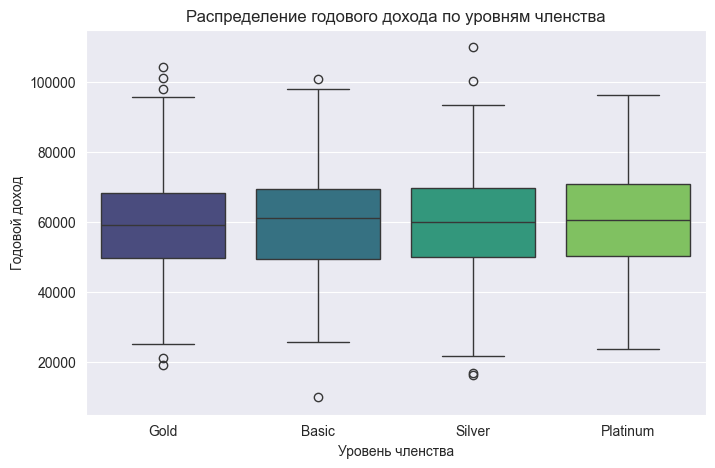

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

FILE_PATH = "data/customer_data_with_churn.csv"
ALPHA = 0.05

try:
    df = pd.read_csv(FILE_PATH)
    print("Файл загружен успешно")
except FileNotFoundError:
    print(f"Ошибка: файл '{FILE_PATH}' не найден")
    exit(1)

print("\n=== ЗАДАНИЕ 1 ===\n")

# диаграмма распределения Annual_Income и проверка на нормальность
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['Annual_Income'], bins=30, kde=True, color='skyblue')
plt.title('Распределение годового дохода')
plt.xlabel('Годовой доход')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
stats.probplot(df['Annual_Income'], dist="norm", plot=plt)
plt.title('Q-Q график')
plt.tight_layout()
plt.show()

# Тест Шапиро-Уилка
stat, p_value = stats.shapiro(df['Annual_Income'].dropna())
print(f"Тест Шапиро-Уилка: p-value = {p_value:.4e}")

if p_value > ALPHA:
    print("Результат: Распределение Annual_Income соответствует НОРМАЛЬНОМУ (p > 0.05)")
else:
    print("Результат: Распределение Annual_Income НЕ является нормальным (p <= 0.05)")

# средние значения по полу с помощью groupby
print("\n--- Средний годовой доход по полу ---")
gender_income = df.groupby('Gender')['Annual_Income'].mean()
print(gender_income)
print(f"Средний доход мужчин: {gender_income['Male']:.2f}")
print(f"Средний доход женщин: {gender_income['Female']:.2f}")

# сравнение средних статистическим тестом
print("\n--- Сравнение среднего дохода мужчин и женщин ---")
male_income = df[df['Gender'] == 'Male']['Annual_Income'].dropna()
female_income = df[df['Gender'] == 'Female']['Annual_Income'].dropna()

if p_value > ALPHA:
    # данные нормальные → t-тест
    t_stat, test_p = stats.ttest_ind(male_income, female_income)
    test_name = "t-тест"
else:
    # данные ненормальные → U-тест Манна-Уитни
    u_stat, test_p = stats.mannwhitneyu(male_income, female_income, alternative='two-sided')
    test_name = "U-тест Манна-Уитни"

print(f"Использован {test_name}: p-value = {test_p:.4e}")

if test_p > ALPHA:
    print("Результат: НЕТ статистически значимых различий в доходе между мужчинами и женщинами")
else:
    print("Результат: ЕСТЬ статистически значимые различия в доходе между мужчинами и женщинами")

print("\n=== ЗАДАНИЕ 2 ===\n")
print("Дисперсионный анализ (ANOVA): проверяем, различается ли доход в зависимости от уровня членства (Membership_Level)")

# Группировка по уровню членства
membership_groups = [group['Annual_Income'].dropna().values for name, group in df.groupby('Membership_Level')]

# Однофакторный ANOVA
f_stat, anova_p = stats.f_oneway(*membership_groups)
print(f"ANOVA: F-статистика = {f_stat:.4f}, p-value = {anova_p:.4e}")

if anova_p > ALPHA:
    print("Результат: Годовой доход НЕ различается в зависимости от уровня членства (p > 0.05)")
else:
    print("Результат: Годовой доход РАЗЛИЧАЕТСЯ в зависимости от уровня членства (p <= 0.05)")

# Дополнительно: выведем средние по уровням для наглядности
print("\nСредний доход по уровням членства:")
print(df.groupby('Membership_Level')['Annual_Income'].mean())

# Визуализация для задания 2
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Membership_Level', y='Annual_Income', palette='viridis')
plt.title('Распределение годового дохода по уровням членства')
plt.xlabel('Уровень членства')
plt.ylabel('Годовой доход')
plt.show()